---
title: "A well-specified linear regression model"
author: "Nguyen Thu Uyen Sarah - nguyet79"
output: html_document
---

In [12]:
library(car) # use vif function for multicollinearity detection
library(lmtest) # use bptest for homoscedasticity test
library(glmnet) # shrinked linear models

In [13]:
# Set default graphics parameters
set_plot_defaults <- function() {
    par(bg="white",
        col="black",
        col.axis="black",
        col.lab="black",
        col.main="black",
        col.sub="black",
        fg="black")
}


In [14]:
d <- read.csv("lreg_data.csv")


Call:
lm(formula = y ~ ., data = d)

Residuals:
     Min       1Q   Median       3Q      Max 
-228.093  -21.041    1.894   24.501  157.924 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept) 148.6082    51.0869   2.909 0.004061 ** 
x1           -0.3404     0.3662  -0.929 0.353880    
x2            0.5223     0.2599   2.010 0.045906 *  
x3           -0.4873     0.6532  -0.746 0.456665    
x4           -2.5976     0.7574  -3.429 0.000742 ***
x5            1.1959     0.5055   2.366 0.019004 *  
x6           -0.3778     1.8612  -0.203 0.839357    
x7           -0.0174     0.2389  -0.073 0.942005    
x8           -0.6565     0.4402  -1.491 0.137543    
x9            1.3295     0.5107   2.603 0.009973 ** 
x10           1.0228     0.2342   4.367 2.08e-05 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 50.29 on 189 degrees of freedom
Multiple R-squared:  0.5803,	Adjusted R-squared:  0.5581 
F-statistic: 26.13 on 10 


	studentized Breusch-Pagan test

data:  full_lm
BP = 34.971, df = 10, p-value = 0.0001263


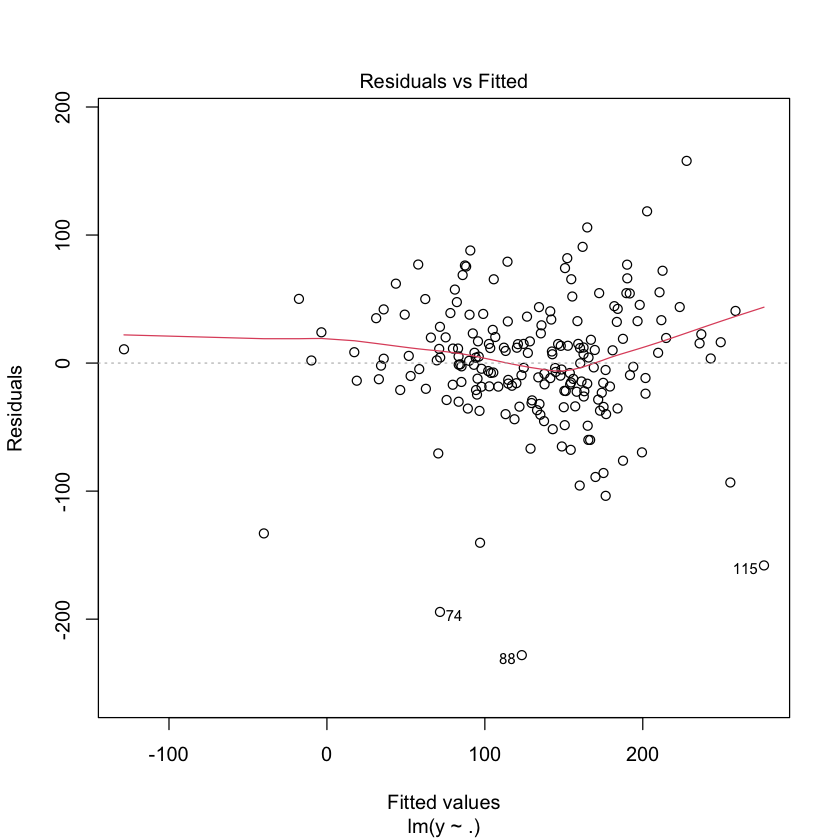


	Shapiro-Wilk normality test

data:  residuals(full_lm)
W = 0.93745, p-value = 1.384e-07


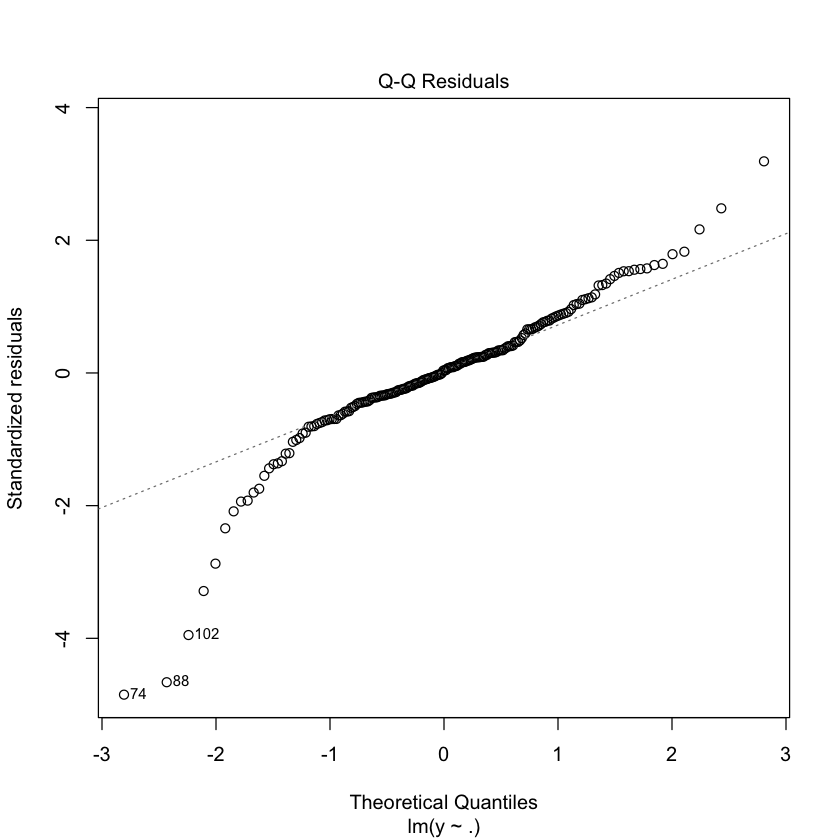

52  74  87  88  98 102 115 129 133 160 165 
 52  74  87  88  98 102 115 129 133 160 165

x1        x2        x3        x4        x5        x6        x7        x8 
 1.057418 10.268698  2.419465  2.143518 10.211986  1.032185  1.036711  1.541193 
       x9       x10 
 1.046448  1.050156

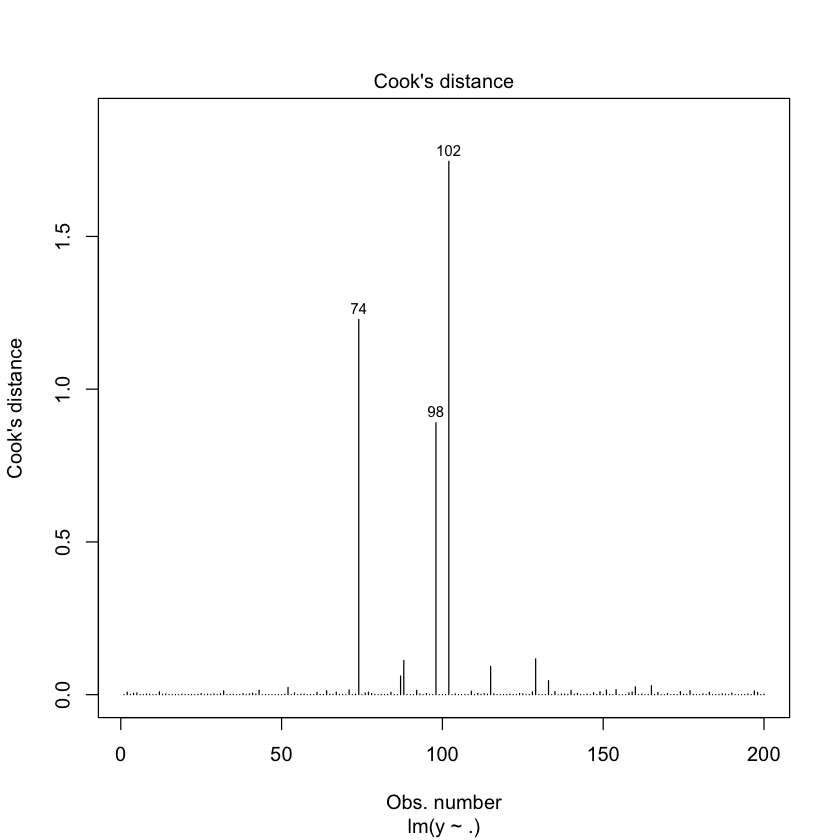

In [15]:
full_lm <- lm(y ~ ., d)
summary(full_lm)

# check for the issues
set_plot_defaults()
# start with the residual plot
plot(full_lm, which=1)

# perform a homoscedasticity test
bptest(full_lm)

# normality of residuals? Q-Q plot and normality test
plot(full_lm, which = 2)  
shapiro.test(residuals(full_lm))

# search for outliers
plot(full_lm, which = 4)
which(cooks.distance(full_lm) > 4 / (nrow(d) - length(coef(full_lm))))

# detect potential multicollinearity
vif(full_lm)

ISSUES: - 
        1) heteroscedasticity: according to Breusch-Pagan test: p-value is 0.0001263  which means that it is significant p<0.001 which means that we can reject homoscedasticity in favor of heteroscedasticity. We can see this in the "Residuals vs Fitted" plot. 
        2) normality test: issue with the normality of residuals. According to Shapiro-Wilk test which sets the p value below 0.05 this indicates that the residuals are not normally distributed. We can see this in the QQ plot as well. The ends are "turned" which means that there are more extreme values than a normal distribution. 
        3) Issue with outliers: we can gain insight on the outliers in the dataset with Cook's distance. We can see that there are 3 major outliers with cook's distance more than approximately 0.9 which indicates that these points have high levarage and are significantly affecting the regression estimates (= influential points).
        4) Issue with multicollinearity -> vif value is >10 in x2 and x5 this indicates that there are problems with multicollinearity ->unstable coefficients and unreliable coefficient estimates


Now deal with the detected issues in the right order. Build an alternative model and show that it works better than the full model. Finally, verbally justify all the decisions that you made and explain their effects.


In [40]:
#1 Remove the outliers
outliers <- which(cooks.distance(full_lm) > 4 / (nrow(d) - length(coef(full_lm))))
d_clean <- d[-outliers, ]

In [41]:
#2 REfit the model without outliers
full_lm_clean <- lm(y ~ ., d_clean)
summary(full_lm_clean)


Call:
lm(formula = y ~ ., data = d_clean)

Residuals:
     Min       1Q   Median       3Q      Max 
-102.776  -19.021    0.461   22.234   83.393 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept) 119.99419   46.09898   2.603 0.010021 *  
x1           -0.45659    0.25958  -1.759 0.080303 .  
x2            0.28441    0.23786   1.196 0.233407    
x3            3.24761    0.92063   3.528 0.000534 ***
x4            0.02917    0.84399   0.035 0.972468    
x5            1.55023    0.46851   3.309 0.001134 ** 
x6           -1.36071    1.34079  -1.015 0.311554    
x7            0.04248    0.16927   0.251 0.802149    
x8           -1.38308    0.44218  -3.128 0.002057 ** 
x9            0.70050    0.37122   1.887 0.060789 .  
x10           0.21821    0.23196   0.941 0.348118    
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 34.78 on 178 degrees of freedom
Multiple R-squared:  0.7156,	Adjusted R-squared:  0.6996 
F-stati

In [43]:
#check multicollinearity
vif(full_lm_clean)

x1        x2        x3        x4        x5        x6        x7        x8 
 1.040165 16.485404  4.950179  4.976241 16.665952  1.047224  1.059139  1.333420 
       x9       x10 
 1.056522  1.204926

In [44]:
#x2 might be causing issues - try removing it
full_lm_improved <- lm(y ~ . - x2, d_clean)
summary(full_lm_improved)


Call:
lm(formula = y ~ . - x2, data = d_clean)

Residuals:
     Min       1Q   Median       3Q      Max 
-103.487  -18.731   -0.133   22.432   80.264 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept) 100.91719   43.30186   2.331 0.020892 *  
x1           -0.45649    0.25989  -1.756 0.080717 .  
x3            3.36142    0.91680   3.666 0.000324 ***
x4            0.09480    0.84321   0.112 0.910608    
x5            2.09279    0.11678  17.921  < 2e-16 ***
x6           -1.14256    1.32991  -0.859 0.391422    
x7            0.02345    0.16872   0.139 0.889635    
x8           -1.18403    0.41013  -2.887 0.004370 ** 
x9            0.72122    0.37126   1.943 0.053633 .  
x10           0.13895    0.22255   0.624 0.533193    
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 34.82 on 179 degrees of freedom
Multiple R-squared:  0.7133,	Adjusted R-squared:  0.6989 
F-statistic: 49.48 on 9 and 179 DF,  p-value: < 2.2e-16


In [51]:
#fix heteroscedasticity with WLS
resid <- residuals(full_lm_improved)
weights <- 1 / (abs(resid))
full_lm_improved <- lm(y ~ . - x2, data = d_clean, weights = weights)
summary(full_lm_improved)



Call:
lm(formula = y ~ . - x2, data = d_clean, weights = weights)

Weighted Residuals:
    Min      1Q  Median      3Q     Max 
-10.112  -4.380   0.023   4.862   8.906 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept) 99.80634    7.04096  14.175  < 2e-16 ***
x1          -0.51648    0.06162  -8.381 1.50e-14 ***
x3           3.14827    0.15633  20.138  < 2e-16 ***
x4          -0.05791    0.11043  -0.524  0.60067    
x5           2.10695    0.03668  57.437  < 2e-16 ***
x6          -1.12461    0.22685  -4.957 1.65e-06 ***
x7          -0.02856    0.02838  -1.006  0.31568    
x8          -1.10228    0.08474 -13.008  < 2e-16 ***
x9           0.84556    0.06968  12.136  < 2e-16 ***
x10          0.10445    0.03478   3.003  0.00306 ** 
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 5.237 on 179 degrees of freedom
Multiple R-squared:  0.9999,	Adjusted R-squared:  0.9999 
F-statistic: 3.802e+05 on 9 and 179 DF,  p-value:


	studentized Breusch-Pagan test

data:  full_lm_improved
BP = 3.0593, df = 9, p-value = 0.9619


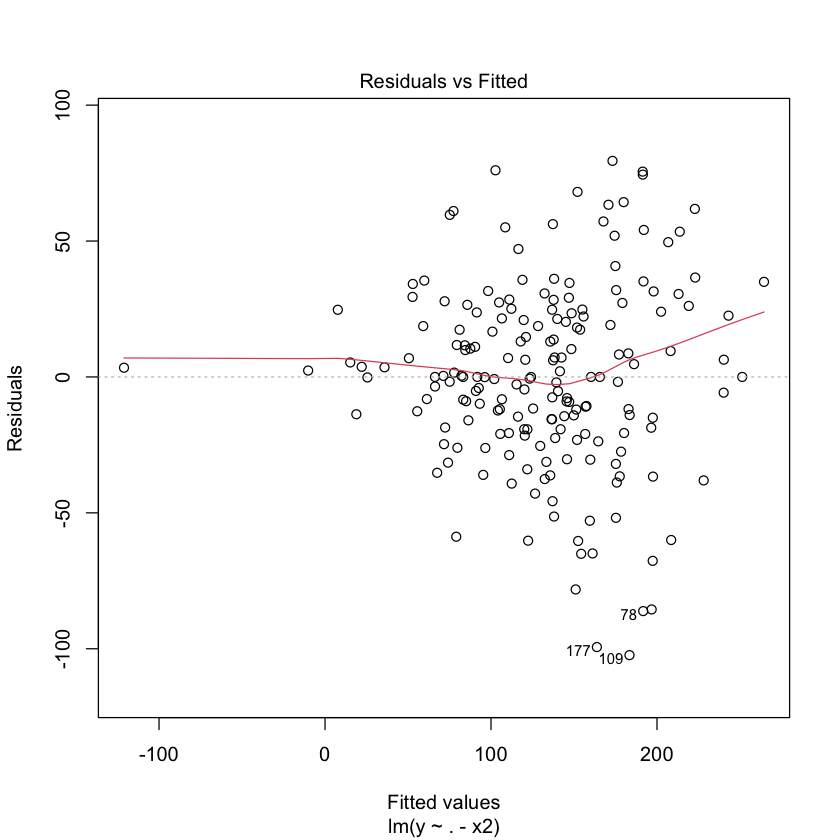


	Shapiro-Wilk normality test

data:  residuals(full_lm_improved)
W = 0.98787, p-value = 0.1059


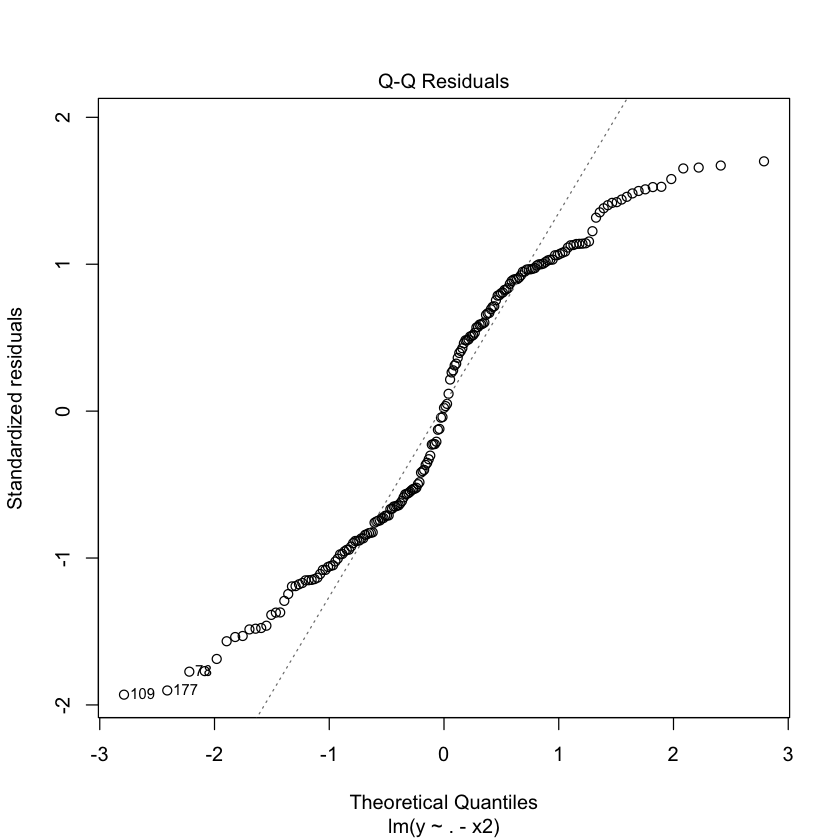

8  28  53 136 173 189 
  8  28  52 127 162 178

x1         x3         x4         x5         x6         x7         x8 
 302.65004 1253.80062  892.74209  521.20867   66.45438  176.87695   41.45004 
        x9        x10 
 101.09639  127.30767

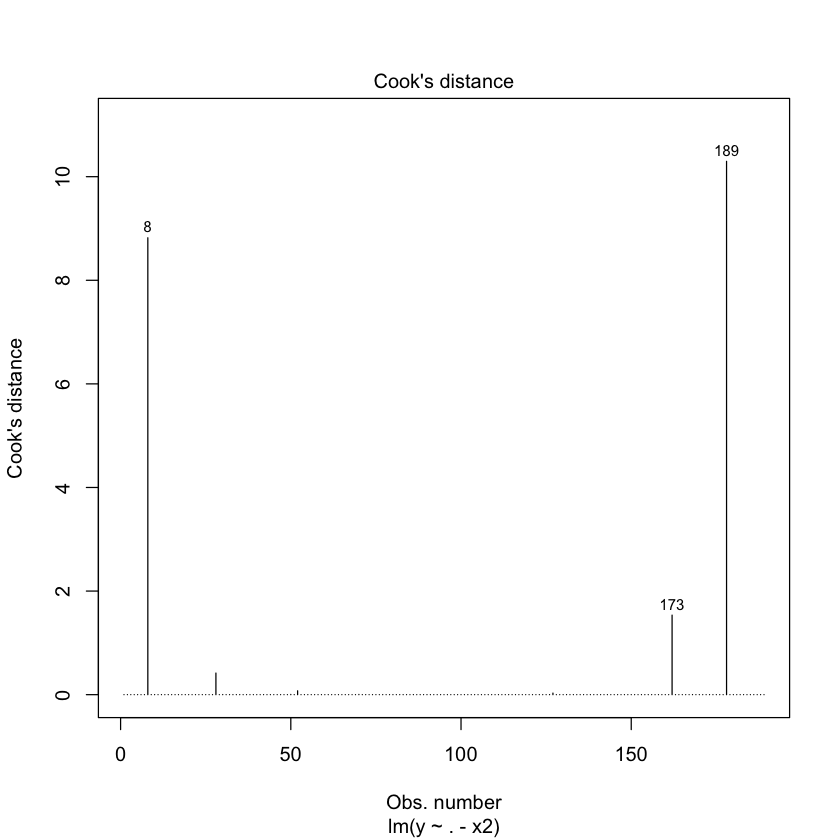

In [50]:
# check for the issues
set_plot_defaults()
# start with the residual plot
plot(full_lm_improved, which=1)

# perform a homoscedasticity test
bptest(full_lm_improved)

# normality of residuals? Q-Q plot and normality test
plot(full_lm_improved, which = 2)  
shapiro.test(residuals(full_lm_improved))

# search for outliers
plot(full_lm_improved, which = 4)
which(cooks.distance(full_lm_improved) > 4 / (nrow(d) - length(coef(full_lm_improved))))

# detect potential multicollinearity
vif(full_lm_improved)

In [53]:
library(caret)


Loading required package: ggplot2

Loading required package: lattice



In [54]:
train_check <- trainControl(method="cv", number=10)
wls_cv <- train(y ~ . - x2, data=d_clean, method="lm", weights=weights, trControl=train_check)
wls_cv

Linear Regression 

189 samples
 10 predictor

No pre-processing
Resampling: Cross-Validated (10 fold) 
Summary of sample sizes: 170, 170, 169, 171, 171, 170, ... 
Resampling results:

  RMSE      Rsquared   MAE     
  33.64904  0.7092274  26.13994

Tuning parameter 'intercept' was held constant at a value of TRUE

The first step I made to improve model was outlier removal according to Cook's distance. Model on the cleaned dataset performed better, this can be seen in the R squared which rose by approximately 0.2. Vif test revealed that x2 and x5 was multicollinear that is why I tried to just remove x2 at first. This step did not improve the model that much, however, it didn't make the model worse either. Nonetheless removing multicollinear variables help with model interpretation and help feature selection methods. I also tried to fix the model by removing the outliers twice, however, it just felt like cherry picking the dataset to fit the model, which is suboptimal. Finally, I tried to fix heteroscedasticity with WLS method. This drastically improved the model, but it improved the model so much I had a suspision it overfitted the data. This is proven with crossvalidation test. So in this part it was not possible to improve the model without feature selection methods. 

The goal now is to perform feature selection and remove irrelevant variables. Compare several different feature selection methods and choose the most appropriate one. Demonstrate that applying feature selection to the full model yields very different results compared to applying it to an alternative model without issues. Finally, explain the selected model.


In [68]:
train_control <- trainControl(method = "cv", number = 10)
forward_model <- train(y ~ ., data = d_clean, method = "leapForward", trControl = train_control)
backward_model <- train(y ~ ., data = d_clean, method = "leapBackward", trControl = train_control)

x <- model.matrix(y ~ ., d_clean)[,-1]
y <- d_clean$y
lasso_model <- train(x,y, method = "glmnet", trControl = train_control, tuneGrid = expand.grid(alpha = 1, lambda = seq(0.001, 1, by = 0.01)))

ridge_model <- train(x,y, method = "glmnet", trControl = train_control, tuneGrid = expand.grid(alpha = 0, lambda = seq(0.001, 1, by = 0.01)))   

result <- resamples(list(Forward=forward_model, Backward=backward_model, Lasso=lasso_model, Ridge=ridge_model))
summary(result)



Call:
summary.resamples(object = result)

Models: Forward, Backward, Lasso, Ridge 
Number of resamples: 10 

MAE 
             Min.  1st Qu.   Median     Mean  3rd Qu.     Max. NA's
Forward  15.94657 22.99596 27.87329 26.94830 31.09589 35.43114    0
Backward 19.03866 24.74155 27.37350 27.11375 30.66200 36.87299    0
Lasso    19.90697 25.41910 27.91642 27.92738 31.10802 36.08884    0
Ridge    16.85208 23.97553 25.85662 28.25937 33.55051 42.74220    0

RMSE 
             Min.  1st Qu.   Median     Mean  3rd Qu.     Max. NA's
Forward  23.13421 30.51913 34.58064 34.50228 39.32588 44.10956    0
Backward 21.06523 32.13916 34.71159 34.62068 38.85096 45.23252    0
Lasso    23.73166 31.51129 35.98496 35.64904 40.30560 44.38112    0
Ridge    21.36979 29.75328 32.19120 35.08839 41.41648 51.33353    0

Rsquared 
              Min.   1st Qu.    Median      Mean   3rd Qu.      Max. NA's
Forward  0.4452901 0.5946279 0.6713076 0.6895745 0.8294345 0.8536179    0
Backward 0.4642707 0.7293844 0.7499165 

It is visible that forward selection outperforms the rest of the models by small margin. However, it is more consistent across resamples, this suggest model stability. 

In [69]:
#get the predictors in each mode
forward_vars <- names(coef(forward_model$finalModel, id = forward_model$bestTune$nvmax))[-1]
num_forward_vars <- length(forward_vars)

backwards_vars <- names(coef(backward_model$finalModel, id = backward_model$bestTune$nvmax))[-1]
num_backward_vars <- length(backwards_vars)

lasso_coef <- coef(lasso_model$finalModel, s = lasso_model$bestTune$lambda)
num_lasso_vars <- sum(lasso_coef != 0) - 1  # subtract 1 to exclude the intercept

ridge_coef <- coef(ridge_model$finalModel, s = ridge_model$bestTune$lambda)
num_ridge_vars <- sum(ridge_coef != 0) - 1  # subtract 1 to exclude the intercept



In [70]:
# Create a summary data frame
summary_df <- data.frame(
  Model = c("Forward", "Backward", "Lasso", "Ridge"),
  Num_Variables = c(num_forward_vars, num_backward_vars, num_lasso_vars, num_ridge_vars)
)

print(summary_df)

# Print variable lists
cat("\nDetailed Variable Lists:\n")
list(
  Forward = forward_vars,
  Backward = backwards_vars,
  Lasso = num_lasso_vars,
  Ridge = num_ridge_vars
)

     Model Num_Variables
1  Forward             3
2 Backward             3
3    Lasso             8
4    Ridge            10

Detailed Variable Lists:


$Forward
[1] "x3" "x5" "x8"

$Backward
[1] "x3" "x5" "x8"

$Lasso
[1] 8

$Ridge
[1] 10

In [71]:
#fit final model with predictors from forward selection
final_formula <- as.formula(paste("y ~", paste(forward_vars, collapse = " + ")))
final_model <- lm(final_formula, data = d_clean)
summary(final_model)


Call:
lm(formula = final_formula, data = d_clean)

Residuals:
     Min       1Q   Median       3Q      Max 
-102.611  -20.690    1.995   21.382   83.117 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  74.9578    25.0126   2.997  0.00310 ** 
x3            3.2772     0.4166   7.866 2.96e-13 ***
x5            2.0847     0.1162  17.941  < 2e-16 ***
x8           -1.2379     0.3869  -3.199  0.00162 ** 
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 34.91 on 185 degrees of freedom
Multiple R-squared:  0.7022,	Adjusted R-squared:  0.6974 
F-statistic: 145.4 on 3 and 185 DF,  p-value: < 2.2e-16



	studentized Breusch-Pagan test

data:  final_model
BP = 32.897, df = 3, p-value = 3.386e-07


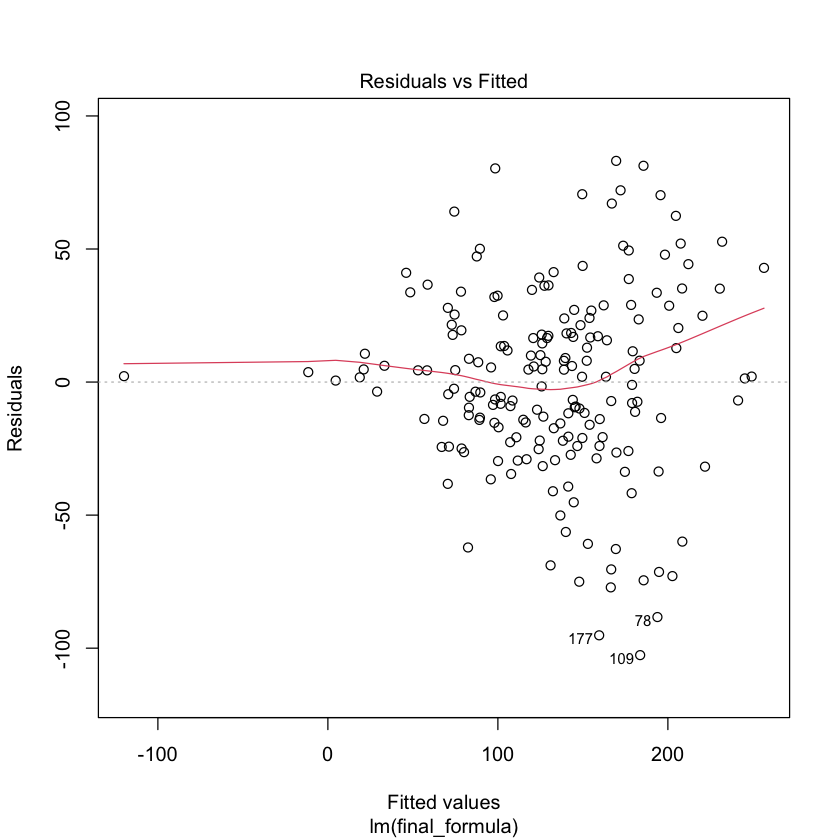


	Shapiro-Wilk normality test

data:  residuals(final_model)
W = 0.98691, p-value = 0.07745


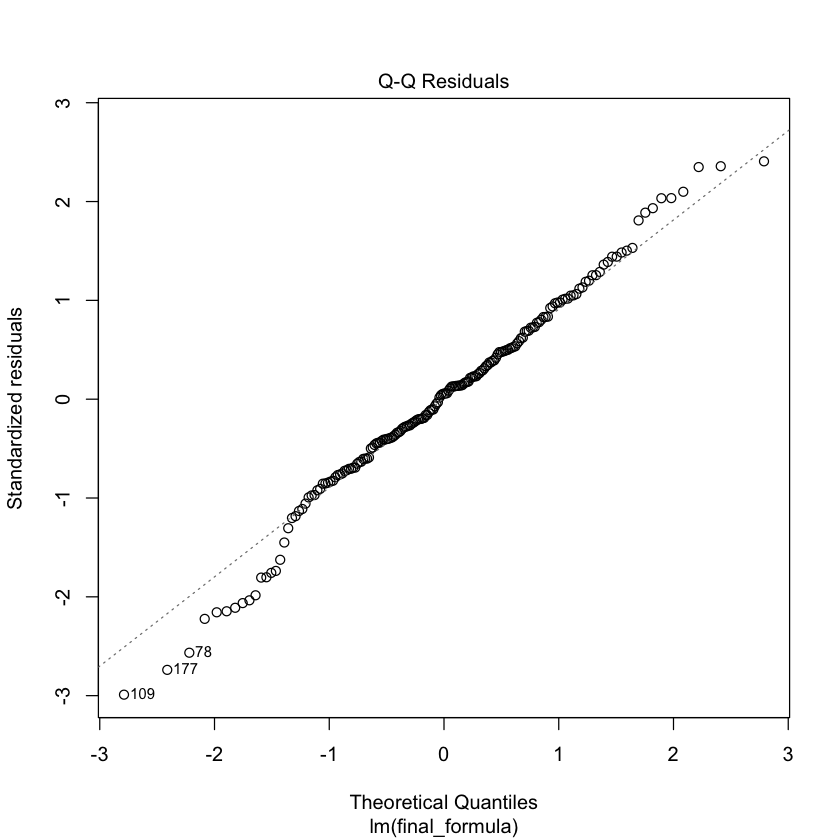

5  43  61  78  92 109 135 140 197 
  5  43  60  76  88 103 126 131 186

x3       x5       x8 
1.006425 1.017625 1.013519

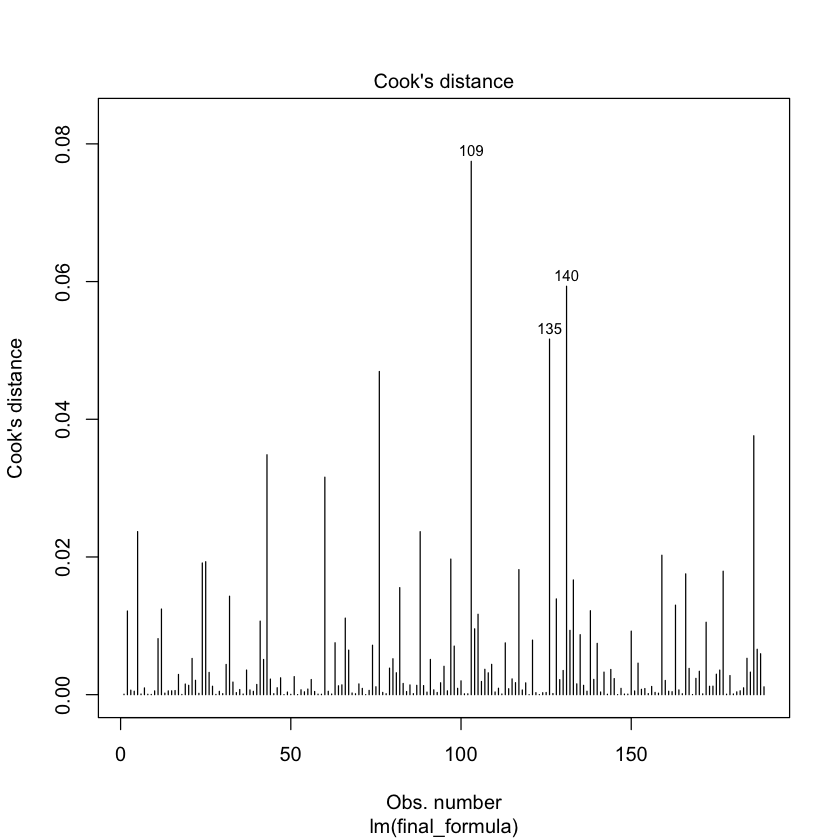

In [72]:
set_plot_defaults()
# start with the residual plot
plot(final_model, which=1)

# perform a homoscedasticity test
bptest(final_model)

# normality of residuals? Q-Q plot and normality test
plot(final_model, which = 2)  
shapiro.test(residuals(final_model))

# search for outliers
plot(final_model, which = 4)
which(cooks.distance(final_model) > 4 / (nrow(d) - length(coef(final_model))))

# detect potential multicollinearity
vif(final_model)

We used four different methods of feature selection: Forward and backward stepwise selection, lasso and ridge. These methods are then compared with ten fold crossvalidation. The results of crossvalidation show, that the best methods are forward stepwise selection and lasso. I have decided between these two methods based on the amount of remaining parameters in the final model. Forward selection has left three parameters and lasso left seven which is why I chose the forward selection, furthermore forward stepwise selection is also more interpretable (x3 and x5 have positive effect on y, while x8 has negative influence). If we use the feature selection on the full model we will get the same amount of predictors, except for ridge, which will always have one more predictor since it cannot nullify. HOwever, the final performance of the model is worse. To summerize what has been done: I deleted the influential points, removed x2 (multicollinearity issue). I have used feature selection on the adjusted model and chose the best one with ten fold crossvalidation. The final model explains 70% variance of data and consists of three predictors, these three predictors contain two with positive effect and one with negative effect on y. Null hypothesis of F-statistic (all coefficients of predictors are 0) is rejected since F statistic is 145.4 on 3 with 185 degrees of freedom and p<2.2e-16.